<div style="display: flex; justify-content: space-between; align-items: center;">
    <img src="../Assets/EUMETSAT_logo.png" alt="EUMETSAT" width="200" height="100">
    <div style="flex-grow: 1;margin-right: 70px;"></div>
    <img src="../Assets/emy_logo.png" alt="HNMS" width="150" height="50">
    <div style="flex-grow: 1; margin-right: 70px;"></div>
    <img src="../Assets/logo-hsaf.png" alt="HSAF" width="300" height="100">
</div>
       Training activity of EUMETSAT and Hellenic National Meteorological Service (HNMS) for HSAF products

---
#### International Autumn School on Satellite Data Analysis, Athens 09 - 13 November 2026
---

# Visualize H-SAF H02B product notebook

### Authors: 
* Ioannis Matsangouras
* Alexandros Paraskevas (alexandros.paraskevas@hnms.gr)

## **Precipitation HSAF Product: P-IN-MHS (H02B)**

**P**= Product is for Precipitaion

**IN**= Type of precipitation , in this case Instantaneous Precipitation Rate

**MHS**= Refers to the radiometer, in this case MHS (Microwave Humidity Sounder)

#### Precipitation rate at ground by MW cross-track scanners AMSU/MHS

Instantaneous precipitation maps from PMW acquisitions by cross-track scanners on operational LEO satellites, processed soon after each satellite pass. Retrieval algorithm based on a neural network trained by means of a pre-computed cloud radiation database built from meteorological situations simulated by a cloud resolving model followed by a radiative transfer model</p>
**Example of H-02B HSAF product:**
<div>
    <img src="../Assets/h02b_1.png" alt="H02" width="40%">
    <img src="../Assets/h02b_2.png" alt="H02_b" width="40%">
</div>

### Precipitation rate at ground by MW cross-track scanners AMSU/MHS
Maps of instantaneous precipitation (mm/hr) generated from MW cross-track scanning radiometers in sun synchronous orbit. Currently processing data from AMSU-A/MHS on board European MetOp and U.S. NOAA satellites

**Coverage:**  Strips of ~ 2250 km swath crossing the MSG 0 Degree Full Disk area [60°S-75°N lat, 60° W-60° E long]

**Cycle:** Up to 8 passes/day (if two Met-Op and two NOAA satellites are available) at approximately 09:30, 01:30, 03:00 ECT (descending mode) and 21:30, 13:30, 15:00 ECT (ascending mode)

**Spatial Resolution:** Corresponds to the nominal resolution of MHS, varying with the viewing scan angle from 16 x 16 km2 / circular at nadir to 26 x 52 km2 / elliptical at scan edge.

**Accuracy:** 
|  Precipitation range | Threshold | Target | Optimal |
|----------------------|-----------|--------|---------|
| >> 10 mm/h           | 90        | 80     | 25      |
|   1-10 mm/h          | 120       | 105    | 50      |
|  < 1 mm/h            | 240       | 145    | 90      |

Accuracy requirements for product P-IN-MHS (RMSE (%), Root Mean Square Error.)

**Timeliness:** 30 min from observing time

**Dissemination:** By dedicated lines to centres connected by GTS - By EUMETCast to most other users, especially scientific

**Formats:** BUFR with values on grid points corresponding to the MHS orbital projection. Also JPEG or similar for quick-look

- **Precipitation Range**: This column specifies different categories of precipitation based on their rates. There are three categories:
   - ">> 10 mm/h" represents precipitation rates greater than 10 millimeters per hour.
   - "1-10 mm/h" represents precipitation rates between 1 and 10 millimeters per hour.
   - "< 1 mm/h" represents precipitation rates less than 1 millimeter per hour.

- **Threshold RMSE (%)**: This column specifies the threshold level of accuracy, represented as the Threshold Root Mean Square Error (RMSE) percentage, for the product "P-IN-MHS" under each precipitation range. For instance, for precipitation rates greater than 10 mm/h, the threshold RMSE is 90%.

- **Target RMSE (%)**: This column specifies the desired level of accuracy, represented as the Target Root Mean Square Error (RMSE) percentage, for the product "P-IN-MHS" under each precipitation range. For instance, for precipitation rates greater than 10 mm/h, the target RMSE should be 80%.

- **Optimal RMSE (%)**: This column represents the ideal or optimal level of accuracy, represented as the Optimal RMSE percentage, for the product "P-IN-MHS" under each precipitation range. In the table, for precipitation rates greater than 10 mm/h, the optimal RMSE should be 25%. Achieving an RMSE equal to or lower than this value would be considered highly desirable.

**Examples:**

- For precipitation rates greater than 10 mm/h, if the product "P-IN-MHS" achieves an RMSE of 70%, it would meet the Target RMSE requirement but not the Optimal RMSE, which is 25%.

- In the 1-10 mm/h precipitation range, the product should aim for an RMSE of 105% to meet the Target requirement, but achieving an RMSE of 50% would be ideal.

- When dealing with precipitation rates of less than 1 mm/h, the product should strive for an RMSE of 90% to meet the Optimal requirement.

More iformation is available to : 
* <a href="https://hsaf.meteoam.it/products/precipitation" target="_blank">Precipitation </a>

## Data Availability

H-02 data are available from ***HSAF*** portal site:

* **HSAF -site:**
Data is stored in raw and jpeg format

Their filename is: *S-HSAF-h02B_20190427_204921_METOPA_64971 (...)*

<div style="display: flex; justify-content: space-between; align-items: center;">
    <img src="../Assets/h02_place_order.png" alt="Image" width="50%">
</div>
    
**Important:** OPERATIONAL DISSEMINATION SUSPENDED FROM 21 July 2026

Further information pertaining to the H-02B product, as well as comprehensive reception details, can be accessed through the following source <a href="https://navigator.eumetsat.int/product/EO:EUM:DAT:0036?query=h02b&&s=advanced" target="_blank">EUMETSAT Product Navigator </a>.
<div>
    <img src="../Assets/H02_user_portal.png" alt="Image" width="90%">

## This module has the following outline
* [1 - Load required libraries](#1---Load-required-libraries)
* [2 - Load data](#2---Load-Data)
* [3 - Define Constants/Variables](#3---Define-Constants/Variables)
* [4 - Generate a plot of H-02B data](#4---Generate-a-plot-of-H-02-data)
* [5 - Get the Rain Rate for the requested lat and lon](#5---Get-the-Rain-Rate-for-the-requested-lat-and-lon)

<h2 id="load_libraries">1 - Load required libraries</h2>

The following libraries are necessary

In [3]:
import gzip
import shutil
import os

import numpy as np
#%pip install xarray
import xarray as xr

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import get_cmap
from matplotlib.colors import ListedColormap
#%pip install cartopy
#%pip install netCDF4
from cartopy import crs as ccrs
import cartopy.feature as cfeature

import datetime

1. **gzip**:
   - The `gzip` module is a Python module for working with GZIP (GNU Zip) compressed files. It provides functions for compression and decompression of files using the GZIP format.

2. **shutil**:
   - The `shutil` module is a Python module that provides a higher-level interface for file operations and manipulation. It includes functions for copying, moving, and deleting files and directories.

3. **os**:
   - The `os` module is a part of the Python standard library and provides functions for interacting with the operating system. It allows you to perform various file and directory operations, manipulate file paths, and more.

4. **numpy**:
   - `numpy` is a fundamental library for scientific computing in Python. It provides support for multidimensional arrays, mathematical functions, and tools for working with arrays, making it a crucial library for data manipulation and numerical computations.

5. **xarray**:
   - `xarray` is a Python library designed for working with labeled multi-dimensional arrays. It is particularly useful for handling and analyzing multidimensional data, such as climate data or time series data.

6. **matplotlib**:
    - `matplotlib` is a popular Python library for creating static, animated, and interactive visualizations. It provides a wide range of functions and tools for creating various types of plots and charts.

7. **cartopy.crs**:
    - `cartopy` is a library for cartographic projections and geospatial data visualization. The `crs` module within Cartopy provides support for defining and working with different coordinate reference systems.

8. **cartopy.feature**:
    - `cartopy.feature` provides a collection of pre-defined geospatial features, such as coastlines, rivers, and political boundaries, that can be used in Cartopy maps to enhance the visualization of geospatial data.
 
9. **datetime**:
    - `datetime` supplies classes to work with date and time. These classes provide a number of functions to deal with dates, times, and time intervals.

## <a id='load_data'></a>2 - Load Data

In [4]:
# Define the Zipped and Unzipped H02 filename
zippedFileName = 'h02B_20230905_072822_METOPC_25051_fdk.nc.gz'

unZippedFileName = zippedFileName.rsplit('.', 1)[0]

# Extract Satellite Name from the Filename
satelliteName = unZippedFileName.split('_')[3]

# Unzip the H02 file and retrieve the data to an xarray dataset
# Open the compressed file for reading ('rb' mode)
with gzip.open('../data/h02'+'/'+zippedFileName, 'rb') as f_in:
    # Create an uncompressed file for writing ('wb' mode)
    with open('../temp/h02'+'/'+unZippedFileName, 'wb') as f_out:
        # Copy the contents of the compressed file to the uncompressed file
        shutil.copyfileobj(f_in, f_out)
# Open and read the data from the uncompressed file using xarray
h02DataSet = xr.open_dataset('../temp/h02'+'/'+unZippedFileName)

#### Explore the data of H-01 product

In [3]:
h02DataSet

<xarray.Dataset> Size: 3MB
Dimensions:  (xc: 1014, yc: 90, zc: 1)
Coordinates:
    lat      (xc, yc) float32 365kB ...
    lon      (xc, yc) float32 365kB ...
Dimensions without coordinates: xc, yc, zc
Data variables:
    utime    (xc, yc) datetime64[ns] 730kB ...
    year     (xc, zc) int32 4kB ...
    time     (xc, zc) int32 4kB ...
    day      (xc, zc) int32 4kB ...
    rr       (xc, yc) float32 365kB ...
    map      (xc, yc) float32 365kB ...
    qind     (xc, yc) int32 365kB ...
    phase    (xc, yc) int32 365kB ...

In [4]:
# Check dimensions and their sizes
print("Dimensions:", h02DataSet.dims)

Dimensions: FrozenMappingWarningOnValuesAccess({'xc': 1014, 'yc': 90, 'zc': 1})


In [5]:
# List variables in the dataset
print("Variables:", h02DataSet.variables)

Variables: Frozen({'utime': <xarray.Variable (xc: 1014, yc: 90)> Size: 730kB
[91260 values with dtype=datetime64[ns]]
Attributes:
    long_name:  time, 'year': <xarray.Variable (xc: 1014, zc: 1)> Size: 4kB
[1014 values with dtype=int32]
Attributes:
    long_name:  year, 'time': <xarray.Variable (xc: 1014, zc: 1)> Size: 4kB
[1014 values with dtype=int32]
Attributes:
    long_name:  time
    units:      millisecond from day start, 'day': <xarray.Variable (xc: 1014, zc: 1)> Size: 4kB
[1014 values with dtype=int32]
Attributes:
    long_name:  julian day number, 'lat': <xarray.Variable (xc: 1014, yc: 90)> Size: 365kB
[91260 values with dtype=float32]
Attributes:
    long_name:  latitude
    units:      degrees_north, 'lon': <xarray.Variable (xc: 1014, yc: 90)> Size: 365kB
[91260 values with dtype=float32]
Attributes:
    long_name:  longitude
    units:      degrees_east, 'rr': <xarray.Variable (xc: 1014, yc: 90)> Size: 365kB
[91260 values with dtype=float32]
Attributes:
    long_name:  rai

In [5]:
# Explore data values of 'rr' (Rainfall Rate)
rr_data = h02DataSet['rr'].values

# Exclude fill value -9.99
rr_no_fill = rr_data[(rr_data >= 0)]

print("Shape of 'rr' data:", rr_data.shape)
print("Mean rr:", np.mean(rr_no_fill))
print("Minimum rr:", np.min(rr_no_fill))
print("Maximum rr:", np.max(rr_data))

Shape of 'rr' data: (1014, 90)
Mean rr: 0.13697933
Minimum rr: 0.0
Maximum rr: 29.38383


## <a id='define_const-vars'></a>3 - Define Constants/Variables

In [7]:
#Extract the 'day', 'year', and 'time' variables
year = h02DataSet.variables['year'][0].item()
dayValue = h02DataSet.variables['day'][0].item()
millisecondsValue = h02DataSet.variables['time'][0].item()

In [8]:
print(year)
print(dayValue)
print(millisecondsValue)

2023
248
26902068


In [9]:
# Convert Julian day to Gregorian date (month and day) and create the date str
jan1 = datetime.datetime(year, 1, 1)
gregorianDate = jan1 + datetime.timedelta(days=dayValue - 1)
month = gregorianDate.strftime("%m")
day = gregorianDate.strftime("%d")
date = f"{year:04d}-{month}-{day}"

# Convert milliseconds to hours and minutes and create the time str
hours = millisecondsValue // (60 * 60 * 1000)
minutes = (millisecondsValue % (60 * 60 * 1000)) // (60 * 1000)
time = f"{hours:02d}:{minutes:02d} UTC"

In [10]:
print(date, time)

2023-09-05 07:28 UTC


In [11]:
# Min threshold for rain rate [mm/hr] to filter out noise
RR_MIN = 0.25 #page 28 of Doc.No: SAF/HSAF/PVR-01/1.1

# Define the area extent for the plot
EXTENT = [10, 40, 30, 50]

# Define the min and max level for the plot
VMIN = 0
VMAX = 30

# Define Fill Value (a commonly used value to indicate missing or undefined data)
fillValue = -9.99

# Define the resolution for the cartopy features (10m resolution for coastline and other map features)
RESOLUTION = '10m'

# Define the colormap (jet colormap with custom modifications)
jet = matplotlib.colormaps['jet']   # Get the 'jet' colormap

# Create a linear gradient of colors from 'jet'
newColors = jet(np.linspace(0, 1, 256))

# Define a semi-transparent white color
white = np.array([256/256, 256/256, 256/256, 0.5])

# Replace the first threshold colors with the semi-transparent white
newColors[:1, :] = white

# Create a new colormap with the modified colors
CMAP = ListedColormap(newColors)

In [12]:
# Filter out values<RR_MIN (produces nan values)
h02DataSet = h02DataSet.where(h02DataSet.rr > RR_MIN)

# Extract the 'rr' variable (rain rate) from the h02DataSet
rr = h02DataSet['rr']
rr = rr.fillna(0) #transform nan values to zero

# Extract the 'lon' variable (longitude) from the h02DataSet
lon = h02DataSet['lon']

# Extract the 'lat' variable (latitude) from the h02DataSet
lat = h02DataSet['lat']

## <a id='gen_save_fig'></a>4 - Generate a plot of H-02 data

* Figure initialization
* Set the extent area and projection
* Add features
* Define the bounds of the data
* Plot the pcolormesh and colorbar
* Save the figure in /out folder

### Full Coverage

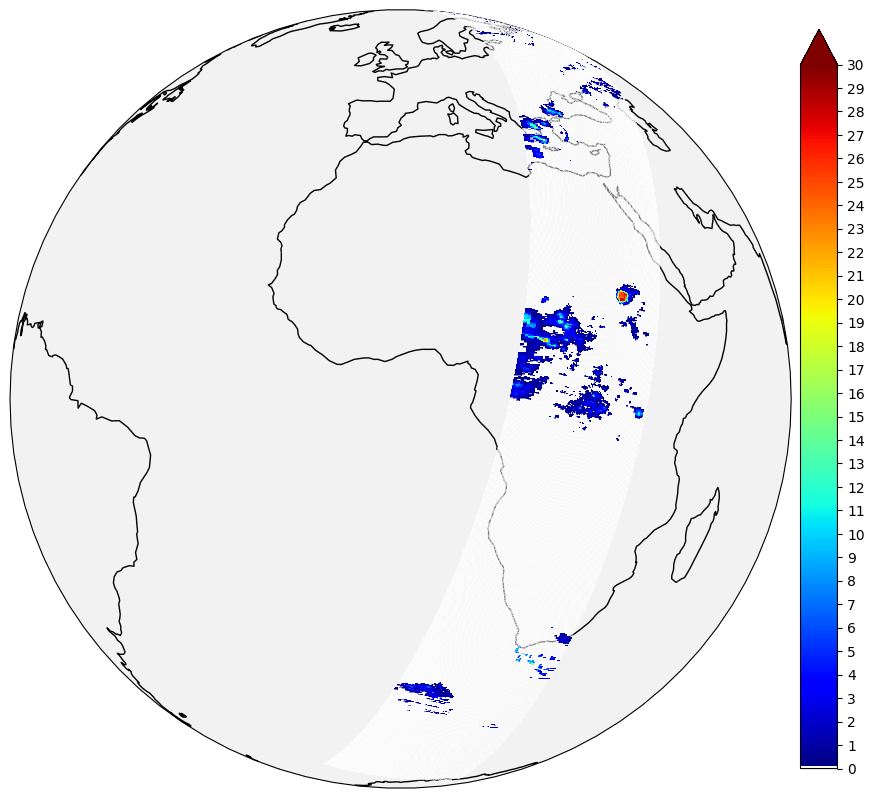

In [13]:
# Initialize the figure
plt.figure(figsize=(12,12)) # Create a figure with a specified size
PROJ = ccrs.Geostationary() # Define the projection (Geostationary projection)
ax = plt.axes(projection=PROJ) # Set the axes
ax.coastlines(resolution='110m') # Add coastline
ax.set_global() # Set global view
ax.set_facecolor('0.95') # Set the facecolor to make swath distinguishable
# Create a pcolormesh plot with specified properties
mapRR = ax.pcolormesh(lon, lat, rr,
                       transform = ccrs.PlateCarree(), vmin=VMIN, vmax=VMAX, cmap=CMAP, zorder=30)
# Define color scale bounds
bounds = np.arange(0,VMAX+1,1)
cbar = plt.colorbar(mapRR, ax=ax, shrink=0.8, pad=.01,  ticks = bounds, extend = 'max')

### Area of Interest

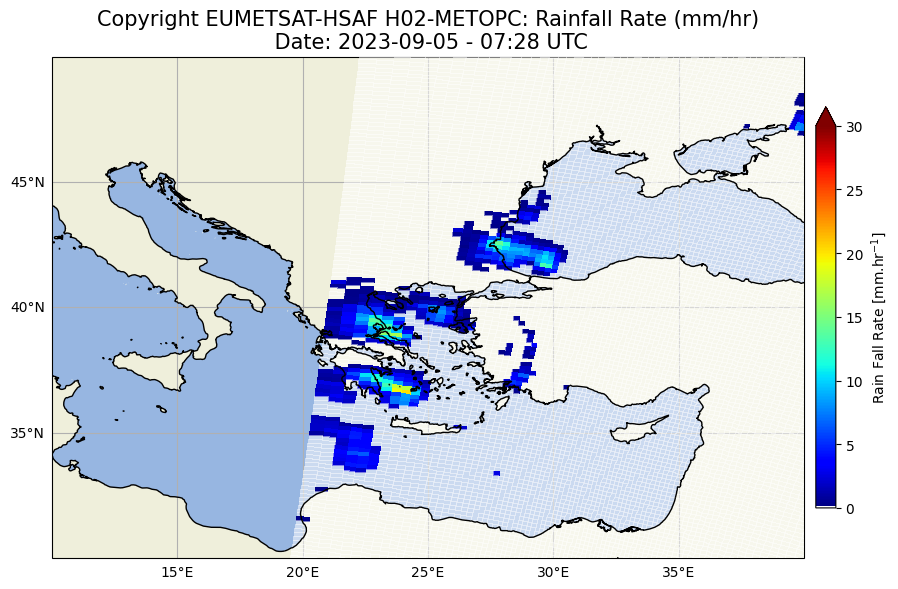

In [14]:
# Initialize the figure
fig = plt.figure(figsize=(12,6))  # Create a figure with a specified size

# Define the projection (Plate Carrée projection)
PROJ = ccrs.PlateCarree()

ax = fig.add_subplot(1,1,1,projection=PROJ)  # Add a subplot with a specified projection

# Set the extent area and projection of the plot
ax.set_extent(EXTENT, PROJ)

# Add ocean, land, coastlines, title, and gridlines features

# Create a NaturalEarthFeature for the ocean with specified properties
feature = cfeature.NaturalEarthFeature(category='physical', name='ocean', scale=RESOLUTION,
                                edgecolor='none',
                                facecolor=cfeature.COLORS['water'],zorder=0)
ax.add_feature(feature)  # Add the ocean feature to the plot

# Create a NaturalEarthFeature for the land with specified properties
feature = cfeature.NaturalEarthFeature(category='physical', name='land', scale=RESOLUTION,
                                edgecolor='none',
                                facecolor=cfeature.COLORS['land'],zorder=1)
ax.add_feature(feature)  # Add the land feature to the plot

ax.coastlines(resolution=RESOLUTION,zorder=100)  # Add coastlines to the plot

# Add a title to the plot
ax.set_title(f"Copyright EUMETSAT-HSAF H02-{satelliteName}: Rainfall Rate (mm/hr)\n \
Date: {date} - {time}", size = 15)  # Set the plot title

# Create gridlines with specified properties
gl = ax.gridlines(draw_labels=True, xlocs=np.arange(EXTENT[0],EXTENT[1],5),
                    ylocs=np.arange(EXTENT[2],EXTENT[3],5), zorder=10)
gl.top_labels = False
gl.right_labels = False

# Plot the pcolormesh

# Define color scale bounds
bounds = np.arange(0,VMAX+1,5)

# Create a pcolormesh plot with specified properties
mapRR = ax.pcolormesh(lon, lat, rr,
                      transform=PROJ, vmin=VMIN, vmax=VMAX, cmap=CMAP, zorder=30)

# Add the colorbar
label = 'Rain Fall Rate [mm.hr$^{-1}$]'
cbar = plt.colorbar(mapRR, ax=ax, shrink=.8, pad=.01, label = label, ticks = bounds, extend = 'max')

fig.tight_layout()  # Adjust the layout of the figure for better appearance

# Save and Show the fig
figPath = os.path.join('../out/h02/',unZippedFileName.rsplit('.')[0]+'.png')
plt.savefig(figPath, format="png", bbox_inches='tight', dpi=150)

## <a id='get_rr'></a>5 - Get the Rain Rate for the requested lat and lon

* Insert the lon and lat
* Find the distance of the requested coords from each [lat,lon] of dataset
* Find the indices of min distance
* Check if distance is lower than the tolerance max distance to avoid accuracy faults
* Print the value and save it, along with metadata, to H02.txt in /out folder

In [15]:
# Define the longitude and latitude to get the respective Rain Fall Rate
targetLon = 22.72
targetLat = 39.14
maxDistance = 0.12 #abou|t 15km (restrict the distance to a neighbor point)

# Find the absolute distance of the target coordinates from the H02 Dataset coordinates
latDiff = np.abs(lat - targetLat)
lonDiff = np.abs(lon - targetLon)

# Keep the indexes of the min distance
latIndex, lonIndex = np.unravel_index((latDiff + lonDiff).argmin(), latDiff.shape)

# Check if the returned distance is in the tolerance max distance 
latDistance = abs(lat[latIndex][lonIndex].item() - targetLat)
lonDistance = abs(lon[latIndex][lonIndex].item() - targetLon)
closeEnough = latDistance < maxDistance and lonDistance < maxDistance

# Print the nearest rainfall rate value to the requested coordinates
nearestRainFallRateValue = rr[latIndex,lonIndex].item() if closeEnough else fillValue
print("Nearest Neighbor Rain Fall Rate value (mm/h) is: {}" .format(nearestRainFallRateValue))

# Save the rainfall rate value to the requested coordinates
with open(os.path.join('../out/h02','H02.txt'), 'a') as f:
    f.write(f"{date} {time} {satelliteName} lon: {lon[latIndex,lonIndex].item()} \
lat: {lat[latIndex,lonIndex].item()} rr: {nearestRainFallRateValue}\n")

Nearest Neighbor Rain Fall Rate value (mm/h) is: 8.706772804260254
